# 02 · Baselines and Out-of-Domain Detection

We establish **non-neural baselines** that every fine-tuned model must beat, and build the **domain gate** the assistant uses to refuse non-medical questions.

| Baseline | MCQ prediction | SAQ prediction |
|---|---|---|
| `baseline_random` | Uniform random option | Random training answer |
| `baseline_majority` | Most frequent gold letter in training | – |
| `baseline_tfidf` | Option with highest TF-IDF cosine to the question + top-5 retrieved training QA pairs | Answer of the nearest training question (TF-IDF) |
| `baseline_minilm_nn` | – | Answer of the nearest training question (MiniLM sentence-embedding cosine, retrieving from the training split only) |

The zero-shot pretrained LLMs (`zs_qwen05`, `zs_qwen15`) are the second level of baseline. They are run on GPU in notebook 03.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import os
os.environ.setdefault("AFRIMED_ROOT", str(ROOT))
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)

In [2]:
from afrimed.baselines import run_baselines
from afrimed.plots import load_all_metrics, results_table
results = run_baselines(use_bertscore=True)
df = load_all_metrics()
results_table(df[df.group == "baseline"]).round(4)

/Users/james/afrimed-assistant/.venv/lib/python3.11/site-packages/sentence_transformers/cross_encoder/CrossEncoder.py:13: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from tqdm.autonotebook import tqdm, trange


Some weights of RobertaModel were not initialized from the model checkpoint at roberta-large and are newly initialized: ['roberta.pooler.dense.bias', 'roberta.pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


/Users/james/afrimed-assistant/.venv/lib/python3.11/site-packages/bert_score/score.py:149: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /Users/runner/work/pytorch/pytorch/pytorch/torch/csrc/utils/tensor_numpy.cpp:212.)
  baselines = torch.from_numpy(


Some weights of RobertaModel were not initialized from the model checkpoint at roberta-large and are newly initialized: ['roberta.pooler.dense.bias', 'roberta.pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Some weights of RobertaModel were not initialized from the model checkpoint at roberta-large and are newly initialized: ['roberta.pooler.dense.bias', 'roberta.pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


baselines finished in 593.3s


,name,group,mcq_accuracy,mcq_macro_f1,mcq_ece,mcq_multi_exact_match,mcq_multi_jaccard,saq_rougeL,saq_bleu,saq_chrf,saq_bertscore_f1,saq_semantic_sim
3,baseline_tfidf,baseline,0.2440,0.2211,0.0440,0.0,0.1777,0.2613,11.0672,30.2036,0.1908,0.4812
0,baseline_majority,baseline,0.2413,0.0778,0.0044,0.0,0.2153,NaN,NaN,NaN,NaN,NaN
2,baseline_random,baseline,0.2091,0.2081,0.0158,0.0,0.2624,0.0771,1.0281,17.9062,-0.0931,0.1636
1,baseline_minilm_nn,baseline,NaN,NaN,NaN,NaN,NaN,0.2431,9.9460,29.9553,0.2060,0.5559


### Interpreting the baselines

* **MCQ:** random guessing gives about 20% (1 in 5 options). Majority-letter gives about 24% because of the answer-position bias found in notebook 01, and its macro-F1 collapses because it only ever predicts one letter. TF-IDF option matching barely beats majority, which shows that the MCQs need reasoning rather than keyword overlap.
* **Multi-answer MCQs (`mcq_multi_exact_match` = 0.0 for every baseline):** all baselines output exactly one letter, so they can never exactly match the 62 test questions with two or more correct options. Their `mcq_multi_jaccard` is above zero because a single correct letter earns partial credit (|pred ∩ gold| / |pred ∪ gold| = 1/k for a question with k correct options). The ordering among baselines on Jaccard (random 0.26 > majority 0.22 > TF-IDF 0.18) is chance-level and not meaningful: there are only 62 such questions, and a single guessed letter is often among the 2–5 correct ones. Jaccard becomes informative only for models that can output several letters, i.e. the fine-tuned LLMs.
* **SAQ:** TF-IDF retrieval scores far above random on ROUGE-L and semantic similarity. Many crowdsourced SAQs are paraphrases of each other ("What is a common traditional remedy for…"), so retrieving a neighbour's answer is a strong lexical baseline. A generative model has to beat it to justify its cost.
* **Negative BERTScore for `baseline_random`:** this is expected, not a bug. BERTScore is computed with `rescale_with_baseline=True` (Zhang et al., 2020), which linearly rescales raw RoBERTa-large F1 using the average score of random sentence pairs from Common Crawl: $\hat{F} = (F - b) / (1 - b)$. After rescaling, unrelated text scores about 0, and slightly worse-than-average pairs go below 0. A random training answer is unrelated to the question, so a value near or below zero is the correct sanity check. Rescaling does not change the ranking of systems; it only makes the scale easier to read.

In [3]:
from afrimed.config import RESULTS_DIR
saq = pd.read_csv(RESULTS_DIR / "baseline_tfidf" / "saq_predictions.csv")
display(saq.sort_values("semantic_sim", ascending=False)[["question", "prediction", "rationale", "semantic_sim"]].head(4))
display(saq.sort_values("semantic_sim")[["question", "prediction", "rationale", "semantic_sim"]].head(4))

,question,prediction,rationale,semantic_sim
17,What is the recommended first-line treatment for uncomplicated acute exacerbation of asthma in children in Africa?,Inhaled short-acting beta agonists (SABAs) such as albuterol or salbutamol are the recommended first-line treatments...,Inhaled short-acting beta agonists (SABAs) such as albuterol or salbutamol are the recommended first-line treatments...,0.977833
167,What is the recommended first-line treatment for uncomplicated acute otitis media in children in Africa?,Amoxicillin or amoxicillin-clavulanate is the first-line medication for treating uncomplicated acute otitis media in...,"Amoxicillin is the recommended first-line treatment for uncomplicated acute otitis media in children in Africa, with...",0.969104
108,What is the first-line treatment for uncomplicated amoebic liver abscess in Africa?,Metronidazole is the first-line treatment for uncomplicated amebic liver abscess in Africa due to its effectiveness ...,Metronidazole is the first-line treatment for uncomplicated amoebic liver abscess in Africa due to its effectiveness...,0.966823
78,What is the primary method used for diagnosing hemolytic anemia associated with liver cirrhosis in Africa?,"Liver function tests, imaging studies such as ultrasound or CT scan, and blood cultures are the primary methods used...","Liver function tests, imaging studies such as ultrasound or CT scan, and liver biopsy are the primary methods used f...",0.938074


,question,prediction,rationale,semantic_sim
179,A 35-year-old lady presented with a six months history of a painful breast lump. The pain was cyclical (premenstrual...,T2N1M0,Fibroadenosis (Fibrocystic disease).,-0.002748
182,Examples of insensible losses and average volume,Aberration in the normal development and involution of the breast. Involves a wide spectrum of benign breast disease...,"Insensible fluid loss is the amount of body fluid lost daily that is not easily measured, from the respiratory syste...",-0.001832
152,What is the primary vector responsible for transmitting malaria in sub-Saharan Africa?,Right iliac fossa pain is the most common symptom,The primary vector responsible for transmitting malaria in sub-Saharan Africa is Anopheles gambiae. \n \nThe reason ...,-0.001377
198,What is the ugly duckling sign and what is its significance?,"Genealogy is crucial in African cultures as it helps trace lineage, maintain cultural identity, and determine inheri...",refers to one mole among many that sticks out and looks different (“the ugly duck”) and should raise suspicion for m...,-0.000812


### Neural retrieval baseline: MiniLM vs TF-IDF

`baseline_minilm_nn` replaces TF-IDF with dense sentence embeddings (`all-MiniLM-L6-v2`). It embeds the 3,783 training questions, finds the training question with the highest cosine similarity to each test SAQ, and returns that question's answer. Retrieval uses the training split only. It sets a stronger bar for the fine-tuned generator: a model that cannot beat "look up the most similar question" adds no value.

In [4]:
cols = ["name", "saq_rougeL", "saq_token_f1", "saq_bleu", "saq_chrf", "saq_bertscore_f1", "saq_semantic_sim", "saq_avg_pred_words"]
display(df[df.name.isin(["baseline_random", "baseline_tfidf", "baseline_minilm_nn"])][cols].round(4))
tf = pd.read_csv(RESULTS_DIR / "baseline_tfidf" / "saq_predictions.csv")
nn = pd.read_csv(RESULTS_DIR / "baseline_minilm_nn" / "saq_predictions.csv")
cmp = tf[["question", "rationale"]].assign(tfidf=tf.prediction, minilm=nn.prediction, tfidf_sim=tf.semantic_sim, minilm_sim=nn.semantic_sim)
cmp["delta"] = cmp.minilm_sim - cmp.tfidf_sim
print(f"MiniLM better on {(cmp.delta > 0).sum()} / {len(cmp)} SAQs, TF-IDF better on {(cmp.delta < 0).sum()}, ties {(cmp.delta == 0).sum()}")
display(cmp.sort_values("delta", ascending=False).head(3))
display(cmp.sort_values("delta").head(3))

,name,saq_rougeL,saq_token_f1,saq_bleu,saq_chrf,saq_bertscore_f1,saq_semantic_sim,saq_avg_pred_words
1,baseline_minilm_nn,0.2431,0.2685,9.9460,29.9553,0.2060,0.5559,27.1260
2,baseline_random,0.0771,0.0930,1.0281,17.9062,-0.0931,0.1636,37.4553
3,baseline_tfidf,0.2613,0.2836,11.0672,30.2036,0.1908,0.4812,28.7967


MiniLM better on 118 / 246 SAQs, TF-IDF better on 49, ties 79


,question,rationale,tfidf,minilm,tfidf_sim,minilm_sim,delta
193,A 68-year-old female with chronic constipation is brought with a history of rapid distension of the abdomen and cons...,Sigmoid Volvulus - a type of Mechanical Intestinal Obstruction,All of the above,a. Sigmoid volvulus,-0.000292,0.783501,0.783794
152,What is the primary vector responsible for transmitting malaria in sub-Saharan Africa?,The primary vector responsible for transmitting malaria in sub-Saharan Africa is Anopheles gambiae. \n \nThe reason ...,Right iliac fossa pain is the most common symptom,"Answer: Vector control measures, including the use of insecticide-treated bed nets and indoor residual spraying. \nR...",-0.001377,0.765631,0.767008
227,Describe how you can manage hyperkalemia,i) Rapidly decrease the risk of life-threatening arrhythmias \n \nii) Shift potassium intracellularly: \n(1) Sodium ...,-Flattened p waves \n-Broad QRS complexes \n-Peaked t waves,Sodium bicarbonate – moves potassium into cell \nSalbutamol – moves potassium into cell \nCalcium gluconate – stabil...,0.007028,0.677683,0.670655


,question,rationale,tfidf,minilm,tfidf_sim,minilm_sim,delta
244,What are the types of placenta previa and what is the treatment option for each,"There are four types of placenta previa, classified based on the location and extent of placental coverage of the in...","Placenta praevia is a pregnancy complication where the placenta partially or completely covers the cervix, the lower...","Type Il posterior, spontaneous vaginal anticipated",0.650104,0.284949,-0.365156
110,What are common occupational health hazards in Africa?,"Agricultural work, mining, and exposure to hazardous chemicals are common occupational health hazards in Africa.","Artisanal mining communities in Africa are exposed to various respiratory hazards including dust, fumes, and toxic c...","Common challenges include limited access to healthcare, poor sanitation, and high rates of infectious diseases like ...",0.697823,0.388995,-0.308828
241,What is acute severe asthma,"Acute severe asthma, also known as status asthmaticus, is a life-threatening medical emergency characterized by: \n ...",Symptoms may include: - Severe wheezing - Coughing - Shortness of breath - Chest tightness - Rapid breathing rate - ...,Stridor. N/A,0.390819,0.085147,-0.305671


**Interpretation.**

* **Dense retrieval finds a semantically better neighbour more often.** MiniLM is better on 118 of 246 SAQs, worse on 49, and ties on 79 (both methods retrieved the same training question). Mean semantic similarity rises from 0.481 to 0.556.
* **The independent metric agrees, modestly.** BERTScore-F1, computed with RoBERTa-large (a different model from the retriever), improves from 0.191 to 0.206. The semantic-similarity metric uses the *same* MiniLM model as the retriever, so its larger gain is partly biased in MiniLM's favour. BERTScore is the fairer comparison.
* **Lexical metrics drop slightly** (ROUGE-L 0.261 → 0.243, BLEU 11.1 → 9.9, chrF about equal). TF-IDF chooses neighbours that share surface words with the question, and those neighbours' answers tend to share words with the reference too, which ROUGE and BLEU reward even when the meaning differs.
* **Where MiniLM wins:** paraphrases with little word overlap. For a clinical vignette describing an elderly woman with rapid abdominal distension, MiniLM retrieves "Sigmoid volvulus" while TF-IDF retrieves an unrelated "All of the above". For the malaria vector question, TF-IDF returned an answer about right iliac fossa pain.
* **Where MiniLM loses:** it retrieves the right *topic* but a neighbour whose answer is terse or answers a different sub-question ("Stridor. N/A" for *What is acute severe asthma?*; a single placenta-previa type instead of the full classification). Retrieval can only be as good as the stored answers, and many crowdsourced answers are short.
* **Takeaway:** MiniLM nearest-neighbour is the stronger retrieval baseline on meaning, and it is the bar the fine-tuned generator must clear (semantic similarity 0.556, BERTScore 0.206). It also supports using MiniLM rather than TF-IDF as the retriever in the RAG experiments.

## Out-of-domain (OOD) detection

The assistant must answer *medical* questions and politely refuse everything else. We frame this as a binary classification task.

* **In-domain (label 1):** AfriMed-QA questions (labelled val/test plus held-out unanswered consumer queries).
* **Out-of-domain (label 0):** real, human-written, non-medical questions from SQuAD v1.1 (Rajpurkar et al., 2016) and WebQuestions (Berant et al., 2013). Articles and questions containing medical keywords are removed. SQuAD validation articles are split *by title* into val/test so the detector is tested on unseen topics, and WebQuestions is used **only for testing** (a different distribution from the OOD training data).

| Method | Score |
|---|---|
| `tfidf_knn` | Max TF-IDF cosine similarity to the in-domain reference questions |
| `embedding_knn` | Max cosine similarity of MiniLM sentence embeddings (Reimers & Gurevych, 2019) |
| `embedding_logreg` | Logistic regression on MiniLM embeddings, trained on in-domain vs SQuAD-train questions |

Thresholds are chosen on the validation set (maximum macro-F1) and then frozen for the test set.

In [5]:
from afrimed.ood import run_ood_experiment
ood_path = RESULTS_DIR / "ood" / "metrics.json"
ood_report = json.loads(ood_path.read_text()) if ood_path.exists() else run_ood_experiment()
pd.DataFrame({k: v for k, v in ood_report.items() if k != "data"}).T.drop(columns="per_source_acceptance").round(4)

,auroc,aupr_in,aupr_out,macro_f1,in_domain_acceptance,ood_rejection,fpr_at_95_tpr,threshold
tfidf_knn,0.732207,0.679601,0.776766,0.643647,0.715767,0.611059,0.897267,0.30396
embedding_knn,0.996978,0.995628,0.998124,0.976448,0.957992,0.989947,0.006598,0.510196
embedding_logreg,0.998935,0.998349,0.999366,0.989873,0.981451,0.995916,0.001885,0.528458


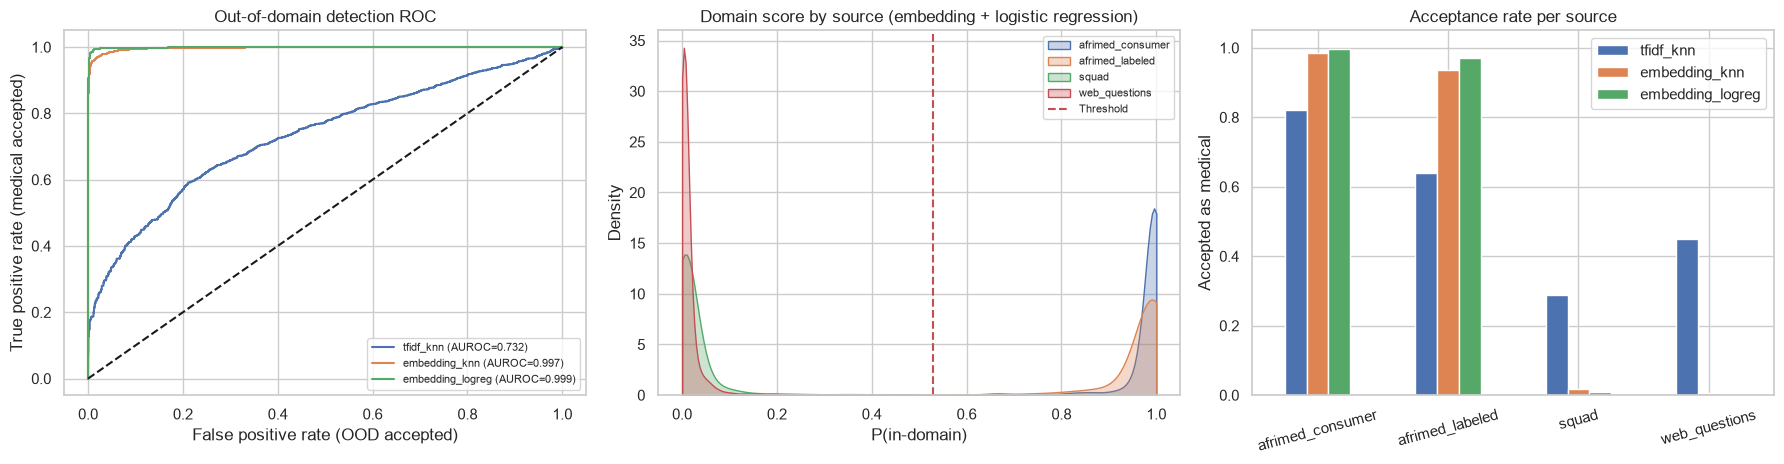

,tfidf_knn,embedding_knn,embedding_logreg
afrimed_consumer,0.8203,0.9859,0.9961
afrimed_labeled,0.6385,0.9374,0.9706
squad,0.2883,0.0183,0.0092
web_questions,0.4498,0.0050,0.0010


In [6]:
from afrimed.plots import plot_ood
plot_ood(); plt.show()
pd.DataFrame({m: ood_report[m]["per_source_acceptance"] for m in ["tfidf_knn", "embedding_knn", "embedding_logreg"]})

### Leakage check: is the gate's reference set isolated from val/test?

The logistic regression and k-NN detectors learn from an *in-domain reference set*: training-split questions plus consumer queries from the official train split. If validation or test questions had leaked into it, the AUROC above would be inflated. This read-only check rebuilds the reference set exactly as in `run_ood_experiment()` and measures (a) exact normalised overlap with val/test and (b) how many reference questions have TF-IDF cosine ≥ 0.9 to any val/test question.

In [7]:
from afrimed.ood import verify_reference_isolation
isolation, ref = verify_reference_isolation(threshold=0.9)
print(json.dumps(isolation, indent=2))
display(ref.sort_values("max_sim_to_heldout", ascending=False).head(10)[["question", "source", "max_sim_to_heldout"]])

{
  "reference_size": 11554,
  "reference_sources": {
    "afrimed_consumer": 7771,
    "afrimed_labeled": 3783
  },
  "heldout_size": {
    "val": 1319,
    "test": 1833
  },
  "exact_overlap_val": 0,
  "exact_overlap_test": 0,
  "reference_with_tfidf_ge_threshold": 9,
  "reference_with_tfidf_ge_threshold_by_source": {
    "afrimed_consumer": 8,
    "afrimed_labeled": 1
  },
  "threshold": 0.9
}


,question,source,max_sim_to_heldout
6726,Are there any lifestyle modifications or preventive measures I can take to reduce the risk of recurring urinary trac...,afrimed_consumer,0.942179
4049,Can it be cured?,afrimed_consumer,0.936042
5014,What risk factors do I have for hypertension?What can I do to lower my risk for hypertension?What is my blood pressure?,afrimed_consumer,0.924136
5909,"What are the warning signs of severe dengue fever, and when should I seek immediate medical attention?",afrimed_consumer,0.917468
868,Risk factors for thyroid cancer,afrimed_labeled,0.916662
6426,What specific measures can I take to manage pain and prevent complications associated with sickle cell anemia?,afrimed_consumer,0.913564
6579,What support services are available to help me cope with the emotional and psychological aspects of living with HIV/...,afrimed_consumer,0.913184
6321,"What are the treatment options available for fibroids, and what are the potential risks and benefits associated with...",afrimed_consumer,0.902683
11246,"""What specific precautions should I take to prevent spreading the infection to others?""",afrimed_consumer,0.901089
4913,Are there any lifestyle changes or preventive measures I can take to reduce the risk of recurrent urinary tract infe...,afrimed_consumer,0.899845


* **(a) Exact overlap is 0** for both validation and test. `in_domain_sources()` builds the reference only from training data and then explicitly removes any question that also appears in val/test.
* **(b) Only 9 of 11,554 reference questions (0.08%)** have TF-IDF cosine ≥ 0.9 to a held-out question. 8 of the 9 are generic consumer-query paraphrases ("Can it be cured?", "What steps can I take to prevent future UTIs?"). Many members of the public independently ask the same generic question, so this is natural paraphrase, not copied rows. With 3,152 in-domain held-out questions, 9 near-paraphrases cannot materially change the AUROC.
* Test questions such as "What is the ugly duckling sign…" appear in the **false-negative** list below precisely because the gate never saw them during training. A leaked question would be expected to score high, not be rejected.
* The real caveat is not leakage but *difficulty*: SQuAD and WebQuestions are clearly non-medical, so the 0.999 AUROC is an upper bound on performance for borderline, health-adjacent questions.

In [8]:
test_scores = pd.read_csv(RESULTS_DIR / "ood" / "test_scores.csv")
thr = ood_report["embedding_logreg"]["threshold"]
fn = test_scores[(test_scores.label == 1) & (test_scores.embedding_logreg < thr)].sort_values("embedding_logreg")
fp = test_scores[(test_scores.label == 0) & (test_scores.embedding_logreg >= thr)].sort_values("embedding_logreg", ascending=False)
display(Markdown("**Medical questions wrongly rejected (false negatives):**"))
display(fn[["question", "source", "embedding_logreg"]].head(10))
display(Markdown("**Non-medical questions wrongly accepted (false positives):**"))
display(fp[["question", "source", "embedding_logreg"]].head(10))

**Medical questions wrongly rejected (false negatives):**

,question,source,embedding_logreg
648,The Monroe-Kellie Doctrine describes which of the following?,afrimed_labeled,0.010658
579,"In DCR, the opening is made at:",afrimed_labeled,0.015243
258,What is the ugly duckling sign and what is its significance?,afrimed_labeled,0.021640
647,What re the four D’s in pellagra disgnosis?,afrimed_labeled,0.024636
716,The concept of the “objective psyche” was proposed by,afrimed_labeled,0.034852
217,Examples of insensible losses and average volume,afrimed_labeled,0.035606
332,78. The MEN II is characterised by,afrimed_labeled,0.049028
1425,If this is her first episode?,afrimed_consumer,0.138548
719,"George plays for one of the best football teams in Ghana. He had a tough time at training, and his coach kept shouti...",afrimed_labeled,0.149446
685,The following are true about Eysenck's theory except,afrimed_labeled,0.154111


**Non-medical questions wrongly accepted (false positives):**

,question,source,embedding_logreg
3021,What physical condition can acute oxygen toxicity cause?,squad,0.988943
2906,What happens when bathocyroe and ocyropsis clap their lobes together?,squad,0.981841
3015,What can a simultaneous hermaphrodite do?,squad,0.906051
2754,Cypiddids are not what?,squad,0.897520
2524,What device is used to treat various conditions such as carbon monoxide poisoning?,squad,0.867804
1897,What has caused Oxfam's findings to be questioned?,squad,0.835328
2834,What protects the statocyst?,squad,0.785393
2563,What is unique about simultaneous hermaphrodites?,squad,0.726686
3443,where is perpignan located?,web_questions,0.702882
3068,what county is frederick md in?,web_questions,0.699482


### What we learned

* Lexical similarity (TF-IDF) is a weak domain detector (AUROC about 0.73): medical and general questions share many surface words ("What is…", "How many…").
* Contextual sentence embeddings separate the domains almost perfectly (AUROC above 0.99), and the trained logistic-regression head is the best and most calibrated. It is the gate deployed in the web app.
* The remaining errors are informative:
  * **Rejected medical questions** are mostly terse exam-style stems or eponyms with no medical keywords ("In DCR, the opening is made at:", "The Monroe-Kellie Doctrine describes which of the following?"), psychology-theory questions, and context-free follow-ups from consumer queries ("If this is her first episode?").
  * **Accepted non-medical questions** come from SQuAD biology and chemistry articles ("What physical condition can acute oxygen toxicity cause?"), which really are health-adjacent.
* SQuAD and WebQuestions are relatively *easy* OOD sets, so performance on borderline, health-adjacent questions (nutrition, fitness, veterinary) is likely lower. This is discussed under limitations.